In [5]:
%matplotlib inline

In [6]:
import pandas as pd

In [7]:
max_legs = 3
trips_thresh = 10

In [25]:
def format_od(od):
    idx_cols = od.columns.tolist()[:-1]
    od.set_index(idx_cols, inplace=True)
    od = od.squeeze()
    return od

In [8]:
def format_optimisation_results(df):
    df[['OrigID', 'DestID', 'Purpose', 'TimePeriod']] = df.ChainDescr.str.split('_', expand=True)
    df.drop('ChainDescr', axis=1, inplace=True)
    return df

In [63]:
def show_tripchains_size_distr(tripchains):
    legs_per_chain = tripchains.groupby('ChainID')['ChainID'].count()
    legs_per_chain.name = 'Legs'
    legs_per_chain.value_counts().plot('bar')
    

In [64]:
def compare_total_trips(base, compare):
    
    total_base = base.sum()
    total_compare = compare.nChains.sum()
    diff_abs = total_compare - total_base
    diff_perc = (total_compare - total_base) / total_base
    
    print('Absolute difference: {:,}'.format(diff_abs))
    print('Percentage difference: {:.1%}'.format(diff_perc))
    

In [65]:
def main(legs, threshold):
    
    infilepath_optimisation_tripchains = r'../optimisation/outputs/results_{}legs_over{}trips.csv'.format(legs, threshold)
    infilepath_tripchains_descrs = r'../tripchain_generation/tripchains_{}legs_over{}trips.csv'.format(legs, threshold)
    infilepath_tripchains_matrix = r'../tripchain_generation/tripchains_od_over{}trips.csv'.format(threshold)

    optimisation_tripchains = pd.read_csv(infilepath_optimisation_tripchains)
    
    tripchain_defs = pd.read_csv(infilepath_tripchains_descrs)
    od = pd.read_csv(infilepath_tripchains_matrix)
    
    optimisation_results = format_optimisation_results(optimisation_tripchains)
    od = format_od(od)
    
    compare_total_trips(od, optimisation_tripchains)
    
    show_tripchains_size_distr(optimisation_tripchains)

Absolute difference: -12,582.0
Percentage difference: -4.0%


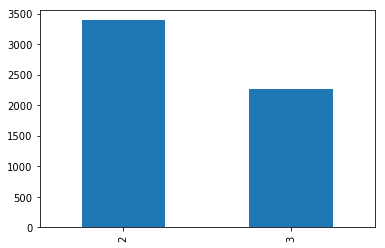

In [76]:
legs = 3
threshold = 10

infilepath_optimisation_tripchains = r'../optimisation/outputs/results_{}legs_over{}trips.csv'.format(legs, threshold)
infilepath_tripchains_descrs = r'../tripchain_generation/tripchains_{}legs_over{}trips.csv'.format(legs, threshold)
infilepath_tripchains_matrix = r'../tripchain_generation/tripchains_od_over{}trips.csv'.format(threshold)

optimisation_tripchains = pd.read_csv(infilepath_optimisation_tripchains)

tripchain_defs = pd.read_csv(infilepath_tripchains_descrs)
od = pd.read_csv(infilepath_tripchains_matrix)

optimisation_tripchains = format_optimisation_results(optimisation_tripchains)
od = format_od(od)

compare_total_trips(od, optimisation_tripchains)

show_tripchains_size_distr(optimisation_tripchains)

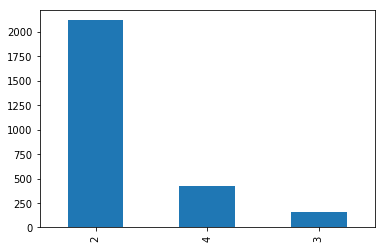

In [72]:
tripchains = optimisation_tripchains

legs_per_chain = tripchains.groupby('ChainID')['ChainID'].count()
legs_per_chain.name = 'Legs'
legs_per_chain.value_counts().plot('bar')


In [69]:
tripchains.head()

,ChainID,nChains,OrigID,DestID,Purpose,TimePeriod
0,18,9,E02000326,E09000030,HB,AM
1,18,9,E02006930,E09000028,NHB,IP
2,18,9,E09000028,E02000326,HB,IP
3,18,9,E09000030,E02006930,NHB,IP
4,36,4,E02000326,E09000030,HB,AM
